In [1]:
import os
from pathlib import Path
# basically if you do Path("example/example2/example.txt") it turns smart and you can do stuff like directory.iterdir() which returns a container of everything in the directory
import numpy as np

import torch
import torch.nn as nn

import cv2
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from sklearn.model_selection import train_test_split

import torchvision.models.video as video_models
from torchvision.models.video import R2Plus1D_18_Weights

from collections import defaultdict

import imageio
import matplotlib.pyplot as plt

In [2]:
datasetpath = "/kaggle/input/datasets/sarbagyashakya/basketball-51-dataset/Basketball_51 dataset"
frames = 16
samplesperclass = 9999 # set to 9999 or some big number for the full dataset

workers = 4
batchsize = 1 # reduced for explaining purposes

modelpath = "/kaggle/input/models/spicybigmac/basketballmodel/pytorch/default/3/final.pt"

savepath = "/kaggle/working/explanations"
alpha = 0.5 # transparency of the heatmap
colormap = cv2.COLORMAP_JET
fps = 8
count = 50

kernelsize = 7
perturbationstep = 0.10 # the top 10% most salient pixels will be blurred

countverify = 1000
sidelen = 60

# determinism stuff
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
torch.backends.cudnn.deterministic = True

In [3]:
# we need to subtract the mean color and divide by the standard deviation of the Kinetics-400 dataset
# this makes it easier to train the model which is already used to these colors

traintrans = v2.Compose([
    v2.Resize([112,112], antialias=True),
    v2.RandomHorizontalFlip(p=0.5),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.43216, 0.394666, 0.37645], std=[0.22803, 0.22145, 0.216989])
])

testtrans = v2.Compose([
    v2.Resize([112,112], antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.43216, 0.394666, 0.37645], std=[0.22803, 0.22145, 0.216989])
])

class BasketballDataset(Dataset):
    def __init__(self, training, datadir, frames=16, samplesperclass=5):
        self.datadir = Path(datadir)
        self.goalframes = frames
        self.training = training
        
        # use sorted here to ensure determinism so the labels arent cooked if the drive is shuffled
        self.classes = sorted([d.name for d in self.datadir.iterdir() if d.is_dir() and not d.name[0] == "."])

        videopaths, labels = [], []

        for i,name in enumerate(self.classes):
            classdir = self.datadir / name

            # use sorted here to ensure determinism so i can debug a specific video index
            vids = sorted([f for f in classdir.iterdir() if f.is_file() and f.suffix.lower() == ".mp4"])

            for path in vids[:samplesperclass]:
                # this only takes the first samplesperclass videos from each class
                videopaths.append(path)
                labels.append(i)

        # self._cache = defaultdict() # cache for less cpu work
        
        # im js a 42-using sheep
        trainpaths, testpaths, trainlabels, testlabels = train_test_split(videopaths, labels, test_size=0.2, stratify=labels, random_state=42)

        if self.training:
            self.videopaths = trainpaths
            self.labels = trainlabels
        else:
            self.videopaths = testpaths
            self.labels = testlabels

        print(f"loaded {len(self.videopaths)} video paths for {'training' if training else 'testing'} :3")

    def __len__(self):
        # dataloader uses this function for like progress bars and stuff
        return len(self.videopaths)

    def __getitem__(self, idx):
        # dataloader always calls this function with idx as the only parameter
        path = self.videopaths[idx]
        label = self.labels[idx]

        frames = self._load_video(path)

        vidtensor = torch.from_numpy(frames)
        # the v2 transform function looks at the last 2 dimensions, so we need to make them height and width respectively
        vidtensor = vidtensor.permute(0,3,1,2)
        if self.training:
            vidtensor = traintrans(vidtensor)
        else:
            vidtensor = testtrans(vidtensor)
        vidtensor = vidtensor.permute(1,0,2,3)

        return vidtensor, label

    def _load_video(self, path):
        cap = cv2.VideoCapture(str(path))
        framecount = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if framecount < self.goalframes:
            # note: this will NEVER HAPPEN unless a video file gets corrupted
            idxs = np.pad(np.arange(framecount), (0, self.goalframes - framecount), mode='edge')
        else:
            idxs = np.linspace(0, framecount - 1, self.goalframes, dtype=int)

        idxs = set(idxs)
        frames = []
        frameidx = 0

        while len(frames) < self.goalframes:
            ret, frame = cap.read()

            if ret:
                if frameidx in idxs:
                    frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB) # convert color
                    frames.append(frame)
            else:
                # videos broken so extend the last working frame otherwise black screen
                while len(frames) < self.goalframes:
                    frames.append(frames[-1] if len(frames) > 0 else np.zeros((int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)), int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), 3), dtype=np.uint8))

            frameidx += 1

        cap.release()
        return np.stack(frames)

In [4]:
traindata = BasketballDataset(True, datasetpath, frames, samplesperclass)
trainloader = DataLoader(traindata, batch_size=batchsize, shuffle=True, num_workers=workers, pin_memory=True, persistent_workers=True)

testdata = BasketballDataset(False, datasetpath, frames, samplesperclass)
testloader = DataLoader(testdata, batch_size=batchsize, shuffle=False, num_workers=workers, pin_memory=True, persistent_workers=True)
# no shuffle for test

classes = len(traindata.classes)

loaded 8248 video paths for training :3
loaded 2063 video paths for testing :3


In [5]:
# loading MY MODEL
model = video_models.r2plus1d_18()

infeatures = model.fc.in_features
model.fc = nn.Linear(infeatures, classes)

statedict = torch.load(modelpath, map_location=torch.device("cpu"))
newstatedict = {}
for k, v in statedict.items():
    nk = k
    if nk.startswith('module.'):
        nk = nk[7:]
    if nk.startswith("fc.0."):
        nk = nk.replace('fc.0.', 'fc.')
    newstatedict[nk] = v

model.load_state_dict(newstatedict)

<All keys matched successfully>

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# if torch.cuda.device_count() > 1:
#     print(f"using {torch.cuda.device_count()} GPUs bless kaggle :praying_hands:")
#     model = nn.DataParallel(model)

model = model.to(device)

print(f"model loaded on {device}")

model loaded on cuda


In [7]:
# explanations time

class GradCam:
    def __init__(self, model, layer):
        self.model = model
        self.layer = layer
        self.grads, self.activations = None, None

        self.forw = layer.register_forward_hook(self.save_activations)
        self.back = layer.register_full_backward_hook(self.save_grads)
        
    def save_activations(self, module, input, output):
        self.activations = output.detach()
    def save_grads(self, module, gradinput, gradoutput):
        self.grads = gradoutput[0].detach()
    
    def remove_hooks(self):
        self.forw.remove()
        self.back.remove()

    def __call__(self, inp, targetclass=None):
        self.model.eval()
        self.model.zero_grad()

        output = self.model(inp)

        if targetclass == None:
            targetclass = output.argmax(dim=1).item()

        score = output[0,targetclass]
        score.backward()

        activations = self.activations[0]
        grads = self.grads[0]
        
        weights = grads.mean(dim=[1,2,3], keepdim=True)

        cam = (weights*activations).sum(dim=0)
        cam = nn.functional.relu(cam)

        cam -= cam.min()
        cam /= (cam.max() + 1e-8)

        t,h,w = inp.shape[2:]
        cam = nn.functional.interpolate(cam.unsqueeze(0).unsqueeze(0), size=[t,h,w], mode="trilinear", align_corners=False)
        cam = cam.squeeze().cpu().numpy()

        prob = torch.softmax(output, dim=1)[0, targetclass].item()
        return cam, targetclass, prob

In [8]:
# helpers

def denormalize(vidtensor, mean, std):
    mean = torch.tensor(mean).view(-1, 1, 1, 1)
    std = torch.tensor(std).view(-1, 1, 1, 1)
    
    vid = vidtensor.cpu() * std + mean
    vid = torch.clamp(vid, 0, 1)
    return vid.numpy()


def frame_to_uint8(frame):
    return (np.clip(frame, 0, 1) * 255).astype(np.uint8)

# generate/save image

def overlay(vid, cam):
    C, T, H, W = vid.shape
    frames = []
    
    for i in range(T):
        frame = np.transpose(vid[:,i,:,:], (1, 2, 0)) # transposes [c,h,w] to [h,w,c]
        if frame.shape[2] == 1:
            # if its black and white 
            frame = np.repeat(frame, 3, axis=2)
        
        # cam for this frame
        camframe = cam[i]
        
        # cam -> heatmap
        heatmap = cv2.applyColorMap(np.uint8(255 * camframe), colormap)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0
        
        # overlap heatmap onto frame
        overlay = frame*(1-alpha) + heatmap*alpha
        overlay = np.clip(overlay, 0, 1)
        
        frames.append(frame_to_uint8(overlay))
    
    return frames


def save_gif(frames, path):
    imageio.mimsave(path, frames, fps=fps)
    print(f"saved gif at: {path}")

# main function

def visualize_gradcam(model, testloader, targetlayer, mean=(0.43216, 0.394666, 0.37645), std=(0.22803, 0.22145, 0.216989)):
    os.makedirs(savepath, exist_ok=True)
    
    # init gradcam
    gradcam = GradCam(model, targetlayer)
    
    out = []
    
    print(f"grad camming in {savepath}")
    
    for videos, labels in testloader:
        videos = videos.to(device)
        labels = labels.cpu().numpy()
        
        for i in range(videos.shape[0]):
            if len(out) >= count:
                break
            
            video = videos[i:i+1]  # keep batch dim for model
            
            # run the gradcam class and prepare frames
            cam, predictedclass, prob = gradcam(video)
            trueclass = int(labels[i])
            
            vid = denormalize(video[0], mean, std)
            overlaid = overlay(vid, cam)
            
            # save gif
            if predictedclass == trueclass:
                gifpath = os.path.join(savepath, f"video_{len(out):03d}_pred{testdata.classes[predictedclass]}_true{testdata.classes[trueclass]}_p{prob:.3%}.gif")
                save_gif(overlaid, gifpath)
                out.append([video[0].cpu().numpy(),cam,predictedclass,prob])

            print(f"video {len(out):3d} | true: {testdata.classes[trueclass]} | predicted: {testdata.classes[predictedclass]} | probability: {prob}")

        if len(out) >= count: break
    
    gradcam.remove_hooks()
    print("completed")

    return out

In [9]:
out = visualize_gradcam(model, testloader, model.layer4)

grad camming in /kaggle/working/explanations
video   0 | true: 3p1 | predicted: 3p0 | probability: 0.8033055067062378
saved gif at: /kaggle/working/explanations/video_000_pred3p0_true3p0_p91.895%.gif
video   1 | true: 3p0 | predicted: 3p0 | probability: 0.9189518690109253
video   1 | true: 3p1 | predicted: 2p1 | probability: 0.9167184233665466
saved gif at: /kaggle/working/explanations/video_001_predft1_trueft1_p98.899%.gif
video   2 | true: ft1 | predicted: ft1 | probability: 0.9889896512031555
saved gif at: /kaggle/working/explanations/video_002_pred3p0_true3p0_p98.725%.gif
video   3 | true: 3p0 | predicted: 3p0 | probability: 0.9872533679008484
saved gif at: /kaggle/working/explanations/video_003_pred3p0_true3p0_p99.489%.gif
video   4 | true: 3p0 | predicted: 3p0 | probability: 0.9948874115943909
saved gif at: /kaggle/working/explanations/video_004_predft1_trueft1_p99.859%.gif
video   5 | true: ft1 | predicted: ft1 | probability: 0.9985866546630859
saved gif at: /kaggle/working/expl

In [10]:
# faithfulness verification

def perturb(vid, mask, kernelsize):
    C, T, H, W = vid.shape
    perturbed = vid.copy()

    for i in range(T):
        frame = vid[:,i,:,:]
        blurred = np.zeros_like(frame)
        for j in range(C):
            blurred[j] = cv2.GaussianBlur(frame[j].astype(np.float32), (kernelsize,kernelsize), 0)

        m = mask[i:i+1,:,:]
        perturbed[:,i,:,:] = frame*(1-m) + blurred*m

    return perturbed

def faithfulness(model, testloader, kernelsize):
    # stores the probabilities for the smart perturbed and the randomly perturbed images
    salient, random = [], [] 

    j = 1
    for vid, cam, predclass, prob in out:
        print(f"\nprocessing video {j}:")

        print(predclass)
        
        currsalient, currrandom = [prob], [prob]
        
        flatcam = cam.flatten()
        pixels = flatcam.shape[0] # should be like 3*16*14*14

        salientidxs = np.argsort(flatcam)[::-1]
        randomidxs = np.random.permutation(pixels)

        for i in range(1,11):
            print(f"perturbing {i*perturbationstep*100}% of frames")
            toblur = int(pixels*i*perturbationstep)
            
            salientmask = np.zeros([pixels])
            salientmask[salientidxs[:toblur]] = 1
            salientmask = salientmask.reshape(cam.shape)

            randommask = np.zeros([pixels])
            randommask[randomidxs[:toblur]] = 1
            randommask = randommask.reshape(cam.shape)

            salienttensor = perturb(vid, salientmask, kernelsize)
            salienttensor = torch.from_numpy(salienttensor).unsqueeze(0).to(device)
            randomtensor = perturb(vid, randommask, kernelsize)
            randomtensor = torch.from_numpy(randomtensor).unsqueeze(0).to(device)

            with torch.no_grad():
                outputsalient = model(salienttensor)
                probsalient = torch.softmax(outputsalient, dim=1)[0, predclass].item()

                outputrandom = model(randomtensor)
                probrandom = torch.softmax(outputrandom, dim=1)[0, predclass].item()

                currsalient.append(probsalient)
                currrandom.append(probrandom)

        salient.append(currsalient)
        random.append(currrandom)
        j += 1

    return salient, random


In [11]:
# get faithfulness

salient, random = faithfulness(model, testloader, kernelsize)

salientavg = np.mean(salient, axis=0)
randomavg = np.mean(random, axis=0)


processing video 1:
2
perturbing 10.0% of frames
perturbing 20.0% of frames
perturbing 30.000000000000004% of frames
perturbing 40.0% of frames
perturbing 50.0% of frames
perturbing 60.00000000000001% of frames
perturbing 70.0% of frames
perturbing 80.0% of frames
perturbing 90.0% of frames
perturbing 100.0% of frames

processing video 2:
5
perturbing 10.0% of frames
perturbing 20.0% of frames
perturbing 30.000000000000004% of frames
perturbing 40.0% of frames
perturbing 50.0% of frames
perturbing 60.00000000000001% of frames
perturbing 70.0% of frames
perturbing 80.0% of frames
perturbing 90.0% of frames
perturbing 100.0% of frames

processing video 3:
2
perturbing 10.0% of frames
perturbing 20.0% of frames
perturbing 30.000000000000004% of frames
perturbing 40.0% of frames
perturbing 50.0% of frames
perturbing 60.00000000000001% of frames
perturbing 70.0% of frames
perturbing 80.0% of frames
perturbing 90.0% of frames
perturbing 100.0% of frames

processing video 4:
2
perturbing 10.

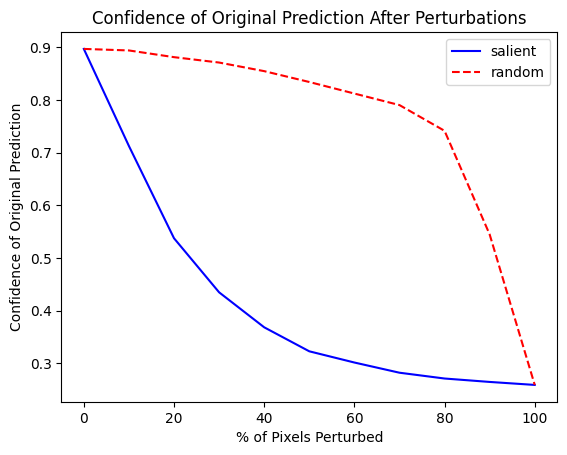

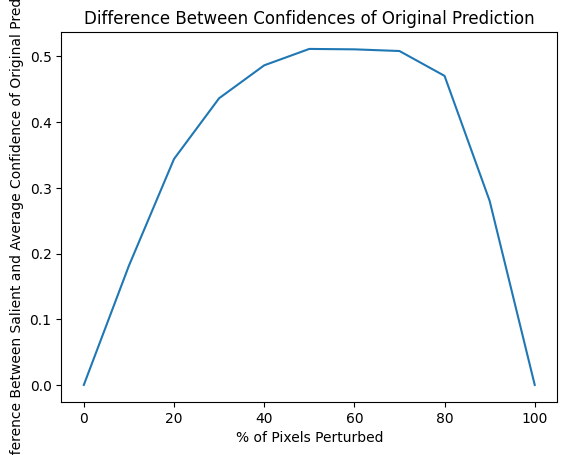

In [12]:
# plot faithfulness

xvals = [i*perturbationstep*100 for i in range(11)]
plt.plot(xvals, salientavg, label="salient", color="blue")
plt.plot(xvals, randomavg, label="random", color="red", ls="--")

plt.xlabel("% of Pixels Perturbed")
plt.ylabel("Confidence of Original Prediction")
plt.title("Confidence of Original Prediction After Perturbations")

plt.legend()
plt.savefig("confidencegraph.png")
plt.show()

diffs = [abs(salientavg[i]-randomavg[i]) for i in range(len(salientavg))]
plt.plot(xvals, diffs)

plt.xlabel("% of Pixels Perturbed")
plt.ylabel("Difference Between Salient and Average Confidence of Original Prediction")
plt.title("Difference Between Confidences of Original Prediction")

plt.savefig("differencegraph.png")
plt.show()

In [13]:
# time to verify that the middle section of the screen actually contributes to accuracy

def blur(vid, mask, kernelsize):
    B, C, T, H, W = vid.shape # B will always be 1
    blurred = vid.copy()

    for i in range(T):
        frame = vid[:,:,i,:,:]
        blurredframe = np.zeros_like(frame)
        for j in range(C):
            blurredframe[0,j] = cv2.GaussianBlur(frame[0,j].astype(np.float32), (kernelsize,kernelsize), 0)

        blurred[:,:,i,:,:] = frame*(1-mask) + blurredframe*mask

    return blurred


def verify(model, testloader, kernelsize, count, sidelen):
    midcorrect, randcorrect = 0,0

    j = 0
    for videos, labels in testloader:
        videos = videos.to(device)
        labels = labels.cpu().numpy()
        
        for i in range(videos.shape[0]):
            if j >= count:
                break

            video = videos[i:i+1].cpu().numpy()

            B, C, T, H, W = video.shape
            
            midmask, randmask = np.zeros_like(video[:,:,0,:,:]), np.zeros_like(video[:,:,0,:,:])
            midmask[:,:,int((H-sidelen)/2):int((H+sidelen)/2),int((W-sidelen)/2):int((W+sidelen)/2)] = 1

            top, left = np.random.randint(0, H-sidelen+1), np.random.randint(0, W-sidelen+1)
            randmask[:,:,top:top+sidelen,left:left+sidelen] = 1
            
            midtensor = torch.from_numpy(blur(video, midmask, kernelsize)).to(device)
            randtensor = torch.from_numpy(blur(video, randmask, kernelsize)).to(device)

            with torch.no_grad():
                _, predmid = model(midtensor).max(1)
                _, predrand = model(randtensor).max(1)

                if (predmid == labels[i]): midcorrect += 1;
                if (predrand == labels[i]): randcorrect += 1;

            j += 1

    return midcorrect/count, randcorrect/count

In [14]:
# middle 50px
midacc, randacc = verify(model, testloader, kernelsize, countverify, sidelen)

In [15]:
print(midacc,randacc)

0.362 0.517


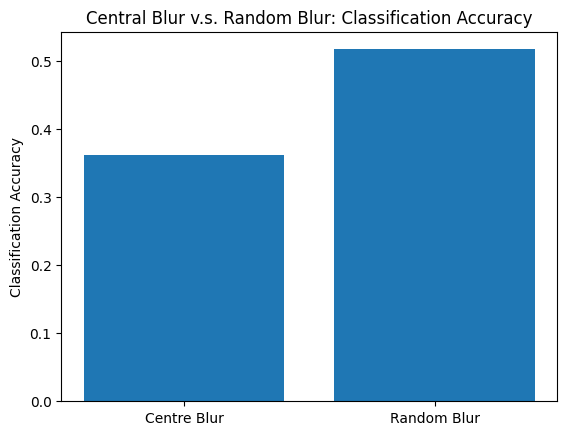

In [16]:
plt.bar(["Centre Blur", "Random Blur"], [midacc, randacc])
plt.ylabel("Classification Accuracy")
plt.title("Central Blur v.s. Random Blur: Classification Accuracy")
plt.savefig("centralvsrandom")
plt.show()